# Transfer Learning and Ensemble Modeling

**Objective:** Apply pretrained deep-learning architectures to image classification with limited data, then combine their predictions using ensemble methods.

**Dataset:** CIFAR-10, downloaded directly through `tf.keras.datasets`.

**Models:** Custom CNN, ImageNet-pretrained ResNet50, and ImageNet-pretrained VGG16.

**Ensemble strategies:** Soft voting (averaging class probabilities) and hard voting (majority vote).

**Colab recommendation:** Runtime → Change runtime type → T4 GPU, if available. This notebook can run on CPU, but training will take longer.

To simulate a limited-data setting, the notebook uses a stratified subset of 10,000 CIFAR-10 training images. The official 10,000-image test set is reserved for final evaluation.

In [1]:
# 1. IMPORT LIBRARIES

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay
)

tf.keras.utils.set_random_seed(42)

print("TensorFlow:", tf.__version__)
print("GPU available:", bool(tf.config.list_physical_devices("GPU")))

TensorFlow: 2.21.0
GPU available: True


## 1. Load CIFAR-10

CIFAR-10 contains 60,000 colour images across 10 categories. Each image is 32 × 32 pixels.

In [5]:
# 2. LOAD DATASET DIRECTLY FROM KERAS

(x_train_full, y_train_full), (x_test, y_test) = (
    tf.keras.datasets.cifar10.load_data()
)

y_train_full = y_train_full.flatten().astype("int64")
y_test = y_test.flatten().astype("int64")
# 2. LOAD AND REDUCE DATASET DIRECTLY FROM KERAS

(x_train_full, y_train_full), (x_test_full, y_test_full) = (
    tf.keras.datasets.cifar10.load_data()
)

y_train_full = y_train_full.flatten().astype("int64")
y_test_full = y_test_full.flatten().astype("int64")

# Select 500 images per class for training
# Select 100 images per class for testing

np.random.seed(42)

train_indices = []
test_indices = []

for class_id in range(10):
    train_class = np.where(y_train_full == class_id)[0]
    test_class = np.where(y_test_full == class_id)[0]

    train_indices.extend(
        np.random.choice(train_class, 500, replace=False)
    )

    test_indices.extend(
        np.random.choice(test_class, 100, replace=False)
    )

x_train = x_train_full[train_indices]
y_train = y_train_full[train_indices]

x_test = x_test_full[test_indices]
y_test = y_test_full[test_indices]

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

print("Reduced Training Data:", x_train.shape)
print("Reduced Testing Data:", x_test.shape)
class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

print("Training data:", x_train_full.shape)
print("Test data:", x_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1883s 11us/step
Reduced Training Data: (5000, 32, 32, 3)
Reduced Testing Data: (1000, 32, 32, 3)
Training data: (50000, 32, 32, 3)
Test data: (1000, 32, 32, 3)


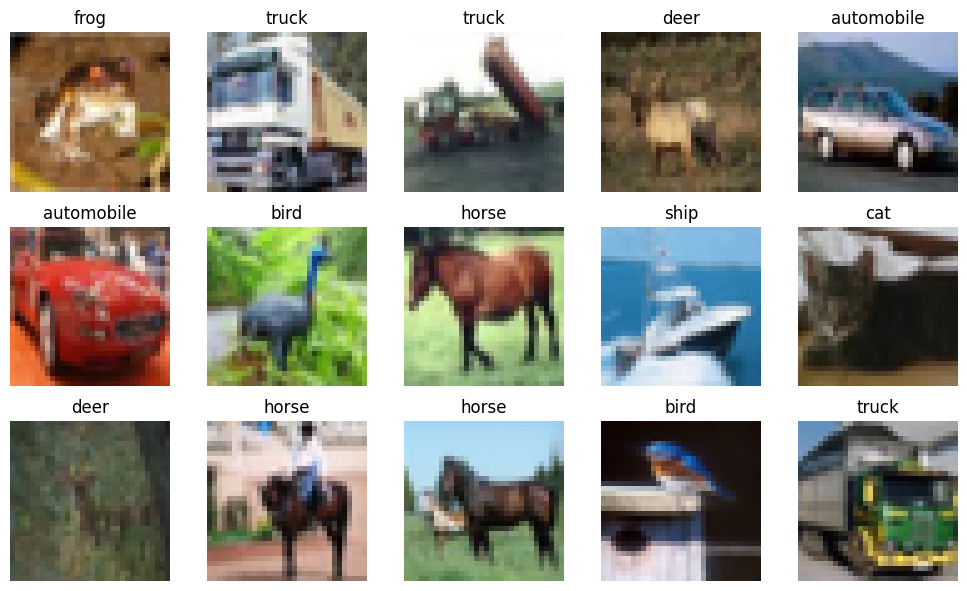

In [6]:
# 3. DISPLAY SAMPLE IMAGES

plt.figure(figsize=(10, 6))
for i in range(15):
    plt.subplot(3, 5, i + 1)
    plt.imshow(x_train_full[i])
    plt.title(class_names[y_train_full[i]])
    plt.axis("off")
plt.tight_layout()
plt.show()

## 2. Create a limited-data split

We select 10,000 images while preserving class balance. These are then divided into training and validation sets. The test set remains separate.

In [7]:
# 4. SELECT 10,000 STRATIFIED TRAINING IMAGES

all_indices = np.arange(len(x_train_full))

subset_indices, _ = train_test_split(
    all_indices,
    train_size=10000,
    stratify=y_train_full,
    random_state=42
)

x_subset = x_train_full[subset_indices]
y_subset = y_train_full[subset_indices]

train_indices, val_indices = train_test_split(
    np.arange(len(x_subset)),
    test_size=0.10,
    stratify=y_subset,
    random_state=42
)

x_train, y_train = x_subset[train_indices], y_subset[train_indices]
x_val, y_val = x_subset[val_indices], y_subset[val_indices]

print("Train:", x_train.shape, y_train.shape)
print("Validation:", x_val.shape, y_val.shape)
print("Test:", x_test.shape, y_test.shape)

Train: (9000, 32, 32, 3) (9000,)
Validation: (1000, 32, 32, 3) (1000,)
Test: (1000, 32, 32, 3) (1000,)


## 3. Prepare input pipelines

The custom CNN uses 32 × 32 images scaled to [0, 1]. ResNet50 and VGG16 use images resized to 96 × 96 with their respective ImageNet preprocessing functions.

In [8]:
# 5. CREATE DATA PIPELINES

BATCH_SIZE = 64
IMAGE_SIZE = 96
AUTOTUNE = tf.data.AUTOTUNE

def make_custom_dataset(images, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((images, labels))
    if training:
        ds = ds.shuffle(len(images), seed=42, reshuffle_each_iteration=True)

    def preprocess(image, label):
        return tf.cast(image, tf.float32) / 255.0, label

    return ds.map(preprocess, num_parallel_calls=AUTOTUNE).batch(
        BATCH_SIZE
    ).prefetch(AUTOTUNE)


def make_pretrained_dataset(images, labels, preprocess_function, training=False):
    ds = tf.data.Dataset.from_tensor_slices((images, labels))
    if training:
        ds = ds.shuffle(len(images), seed=42, reshuffle_each_iteration=True)

    def preprocess(image, label):
        image = tf.cast(image, tf.float32)
        image = tf.image.resize(image, (IMAGE_SIZE, IMAGE_SIZE))
        return preprocess_function(image), label

    return ds.map(preprocess, num_parallel_calls=AUTOTUNE).batch(
        BATCH_SIZE
    ).prefetch(AUTOTUNE)


# Custom CNN datasets
train_custom_ds = make_custom_dataset(x_train, y_train, training=True)
val_custom_ds = make_custom_dataset(x_val, y_val)
test_custom_ds = make_custom_dataset(x_test, y_test)

# ResNet50 datasets
resnet_preprocess = tf.keras.applications.resnet50.preprocess_input
train_resnet_ds = make_pretrained_dataset(
    x_train, y_train, resnet_preprocess, training=True
)
val_resnet_ds = make_pretrained_dataset(x_val, y_val, resnet_preprocess)
test_resnet_ds = make_pretrained_dataset(x_test, y_test, resnet_preprocess)

# VGG16 datasets
vgg_preprocess = tf.keras.applications.vgg16.preprocess_input
train_vgg_ds = make_pretrained_dataset(
    x_train, y_train, vgg_preprocess, training=True
)
val_vgg_ds = make_pretrained_dataset(x_val, y_val, vgg_preprocess)
test_vgg_ds = make_pretrained_dataset(x_test, y_test, vgg_preprocess)

print("Data pipelines are ready.")

Data pipelines are ready.


## 4. Model 1 — Custom CNN

The custom CNN is trained from scratch and acts as the baseline for comparison.

In [9]:
# 6. BUILD THE CUSTOM CNN

def build_custom_cnn():
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(32, 32, 3)),
        tf.keras.layers.Conv2D(32, 3, padding="same", activation="relu"),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Conv2D(64, 3, padding="same", activation="relu"),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Conv2D(128, 3, padding="same", activation="relu"),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.GlobalAveragePooling2D(),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(128, activation="relu"),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(10, activation="softmax")
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

custom_model = build_custom_cnn()
custom_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,050 (433.79 KB)

 Trainable params: 111,050 (433.79 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
# 7. TRAIN THE CUSTOM CNN

history_custom = custom_model.fit(
    train_custom_ds,
    validation_data=val_custom_ds,
    epochs=8,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_accuracy", patience=3,
            mode="max", restore_best_weights=True
        )
    ],
    verbose=1
)

Epoch 1/8
141/141 ━━━━━━━━━━━━━━━━━━━━ 22s 92ms/step - accuracy: 0.1813 - loss: 2.1531 - val_accuracy: 0.2570 - val_loss: 1.9367
Epoch 2/8
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.2729 - loss: 1.8859 - val_accuracy: 0.3470 - val_loss: 1.7167
Epoch 3/8
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.3230 - loss: 1.7762 - val_accuracy: 0.3990 - val_loss: 1.6212
Epoch 4/8
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.3750 - loss: 1.6626 - val_accuracy: 0.4120 - val_loss: 1.5458
Epoch 5/8
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.3887 - loss: 1.6302 - val_accuracy: 0.4250 - val_loss: 1.5485
Epoch 6/8
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.4181 - loss: 1.5483 - val_accuracy: 0.4820 - val_loss: 1.4324
Epoch 7/8
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.4477 - loss: 1.4968 - val_accuracy: 0.4980 - val_loss: 1.3925
Epoch 8/8
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.4580 - loss: 1.4442 - val_accuracy: 0.5230 -

## 5. Model 2 — Transfer learning with ResNet50

ResNet50 is loaded with ImageNet weights and without its original classification layer. First, the pretrained feature extractor is frozen while a new 10-class head is trained. Then the final layers are unfrozen and fine-tuned with a small learning rate.

In [11]:
# 8. LOAD RESNET50 AND ADD A CUSTOM CLASSIFICATION HEAD

resnet_base = tf.keras.applications.ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3)
)
resnet_base.trainable = False

resnet_inputs = tf.keras.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3))
x = resnet_base(resnet_inputs, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)
x = tf.keras.layers.Dense(128, activation="relu")(x)
x = tf.keras.layers.Dropout(0.2)(x)
resnet_outputs = tf.keras.layers.Dense(10, activation="softmax")(x)

resnet_model = tf.keras.Model(
    resnet_inputs, resnet_outputs, name="ResNet50_transfer"
)
resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
resnet_model.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step


Model: "ResNet50_transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 3, 3, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,851,274 (90.99 MB)

 Trainable params: 263,562 (1.01 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [12]:
# 9. TRAIN RESNET50 HEAD WITH FEATURE EXTRACTOR FROZEN

history_resnet_head = resnet_model.fit(
    train_resnet_ds,
    validation_data=val_resnet_ds,
    epochs=4,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_accuracy", patience=2,
            mode="max", restore_best_weights=True
        )
    ],
    verbose=1
)

Epoch 1/4
141/141 ━━━━━━━━━━━━━━━━━━━━ 47s 189ms/step - accuracy: 0.7044 - loss: 0.9092 - val_accuracy: 0.8220 - val_loss: 0.4968
Epoch 2/4
141/141 ━━━━━━━━━━━━━━━━━━━━ 6s 42ms/step - accuracy: 0.8086 - loss: 0.5480 - val_accuracy: 0.8180 - val_loss: 0.5055
Epoch 3/4
141/141 ━━━━━━━━━━━━━━━━━━━━ 10s 38ms/step - accuracy: 0.8351 - loss: 0.4676 - val_accuracy: 0.8390 - val_loss: 0.4636
Epoch 4/4
141/141 ━━━━━━━━━━━━━━━━━━━━ 6s 42ms/step - accuracy: 0.8602 - loss: 0.3965 - val_accuracy: 0.8430 - val_loss: 0.4570


In [13]:
# 10. FINE-TUNE THE FINAL RESNET50 LAYERS

resnet_base.trainable = True

# Freeze most layers; leave only the final 30 layers trainable.
for layer in resnet_base.layers[:-30]:
    layer.trainable = False

# Keep Batch Normalization layers frozen for stable fine-tuning.
for layer in resnet_base.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_resnet_finetune = resnet_model.fit(
    train_resnet_ds,
    validation_data=val_resnet_ds,
    epochs=3,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_accuracy", patience=2,
            mode="max", restore_best_weights=True
        )
    ],
    verbose=1
)

Epoch 1/3
141/141 ━━━━━━━━━━━━━━━━━━━━ 41s 164ms/step - accuracy: 0.8920 - loss: 0.3084 - val_accuracy: 0.8570 - val_loss: 0.4226
Epoch 2/3
141/141 ━━━━━━━━━━━━━━━━━━━━ 15s 50ms/step - accuracy: 0.9191 - loss: 0.2233 - val_accuracy: 0.8590 - val_loss: 0.4253
Epoch 3/3
141/141 ━━━━━━━━━━━━━━━━━━━━ 7s 53ms/step - accuracy: 0.9423 - loss: 0.1650 - val_accuracy: 0.8690 - val_loss: 0.4495


## 6. Model 3 — Transfer learning with VGG16

VGG16 is configured similarly. Its feature extractor is frozen while the custom head is trained, then the final convolutional block is fine-tuned.

In [14]:
# 11. LOAD VGG16 AND ADD A CUSTOM CLASSIFICATION HEAD

vgg_base = tf.keras.applications.VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3)
)
vgg_base.trainable = False

vgg_inputs = tf.keras.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3))
x = vgg_base(vgg_inputs, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)
x = tf.keras.layers.Dense(128, activation="relu")(x)
x = tf.keras.layers.Dropout(0.2)(x)
vgg_outputs = tf.keras.layers.Dense(10, activation="softmax")(x)

vgg_model = tf.keras.Model(
    vgg_inputs, vgg_outputs, name="VGG16_transfer"
)
vgg_model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
vgg_model.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


Model: "VGG16_transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 3, 3, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,781,642 (56.39 MB)

 Trainable params: 66,954 (261.54 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [15]:
# 12. TRAIN VGG16 HEAD WITH FEATURE EXTRACTOR FROZEN

history_vgg_head = vgg_model.fit(
    train_vgg_ds,
    validation_data=val_vgg_ds,
    epochs=4,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_accuracy", patience=2,
            mode="max", restore_best_weights=True
        )
    ],
    verbose=1
)

Epoch 1/4
141/141 ━━━━━━━━━━━━━━━━━━━━ 34s 151ms/step - accuracy: 0.4900 - loss: 2.7785 - val_accuracy: 0.7120 - val_loss: 0.8761
Epoch 2/4
141/141 ━━━━━━━━━━━━━━━━━━━━ 9s 61ms/step - accuracy: 0.6277 - loss: 1.1881 - val_accuracy: 0.7360 - val_loss: 0.7790
Epoch 3/4
141/141 ━━━━━━━━━━━━━━━━━━━━ 10s 57ms/step - accuracy: 0.6763 - loss: 0.9770 - val_accuracy: 0.7660 - val_loss: 0.6965
Epoch 4/4
141/141 ━━━━━━━━━━━━━━━━━━━━ 8s 58ms/step - accuracy: 0.7104 - loss: 0.8703 - val_accuracy: 0.7660 - val_loss: 0.6722


In [16]:
# 13. FINE-TUNE THE FINAL VGG16 CONVOLUTIONAL BLOCK

vgg_base.trainable = True

for layer in vgg_base.layers:
    layer.trainable = layer.name.startswith("block5")

vgg_model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_vgg_finetune = vgg_model.fit(
    train_vgg_ds,
    validation_data=val_vgg_ds,
    epochs=3,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_accuracy", patience=2,
            mode="max", restore_best_weights=True
        )
    ],
    verbose=1
)

Epoch 1/3
141/141 ━━━━━━━━━━━━━━━━━━━━ 24s 120ms/step - accuracy: 0.7257 - loss: 0.8159 - val_accuracy: 0.8190 - val_loss: 0.5796
Epoch 2/3
141/141 ━━━━━━━━━━━━━━━━━━━━ 10s 72ms/step - accuracy: 0.7783 - loss: 0.6556 - val_accuracy: 0.8190 - val_loss: 0.5290
Epoch 3/3
141/141 ━━━━━━━━━━━━━━━━━━━━ 10s 73ms/step - accuracy: 0.8154 - loss: 0.5392 - val_accuracy: 0.8450 - val_loss: 0.4757


## 7. Evaluate the individual models

Each model is evaluated on the same held-out CIFAR-10 test set.

In [17]:
# 14. GENERATE TEST-SET PREDICTIONS

custom_prob = custom_model.predict(test_custom_ds, verbose=1)
resnet_prob = resnet_model.predict(test_resnet_ds, verbose=1)
vgg_prob = vgg_model.predict(test_vgg_ds, verbose=1)

custom_pred = np.argmax(custom_prob, axis=1)
resnet_pred = np.argmax(resnet_prob, axis=1)
vgg_pred = np.argmax(vgg_prob, axis=1)

custom_acc = accuracy_score(y_test, custom_pred)
resnet_acc = accuracy_score(y_test, resnet_pred)
vgg_acc = accuracy_score(y_test, vgg_pred)

individual_results = pd.DataFrame({
    "Model": ["Custom CNN", "ResNet50", "VGG16"],
    "Test Accuracy": [custom_acc, resnet_acc, vgg_acc]
})

display(individual_results)

16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step
16/16 ━━━━━━━━━━━━━━━━━━━━ 9s 275ms/step
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 92ms/step


,Model,Test Accuracy
0,Custom CNN,0.476
1,ResNet50,0.860
2,VGG16,0.799


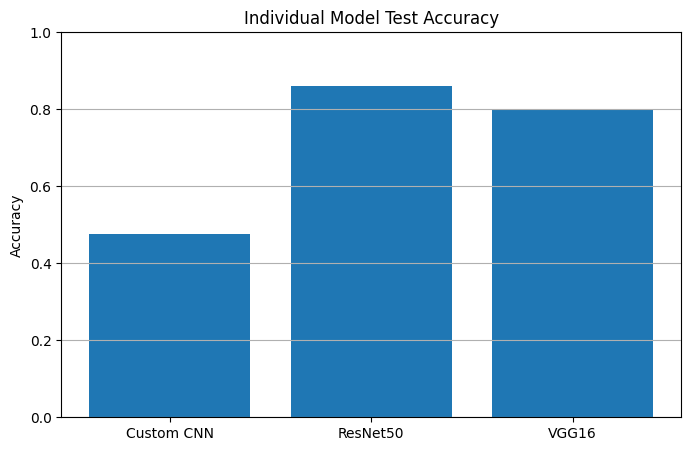

In [18]:
# 15. PLOT INDIVIDUAL MODEL ACCURACY

plt.figure(figsize=(8, 5))
plt.bar(individual_results["Model"], individual_results["Test Accuracy"])
plt.title("Individual Model Test Accuracy")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.grid(axis="y")
plt.show()

## 8. Ensemble modeling

**Soft voting:** Average the three models' class-probability vectors and choose the class with the highest average probability.

**Hard voting:** Each model votes for one class. The class receiving the most votes is selected.

In [19]:
# 16. SOFT VOTING (PROBABILITY AVERAGING)

ensemble_prob = (custom_prob + resnet_prob + vgg_prob) / 3.0
soft_voting_pred = np.argmax(ensemble_prob, axis=1)

soft_voting_accuracy = accuracy_score(y_test, soft_voting_pred)
print("Soft Voting Test Accuracy:", round(soft_voting_accuracy, 4))

Soft Voting Test Accuracy: 0.871


In [20]:
# 17. HARD VOTING (MAJORITY VOTING)

individual_predictions = np.stack(
    [custom_pred, resnet_pred, vgg_pred], axis=1
)

hard_voting_pred = []
for row in individual_predictions:
    vote_counts = np.bincount(row, minlength=10)
    hard_voting_pred.append(np.argmax(vote_counts))

hard_voting_pred = np.asarray(hard_voting_pred)
hard_voting_accuracy = accuracy_score(y_test, hard_voting_pred)

print("Hard Voting Test Accuracy:", round(hard_voting_accuracy, 4))

Hard Voting Test Accuracy: 0.83


,Model,Test Accuracy
3,Soft Voting Ensemble,0.871
1,ResNet50,0.860
4,Hard Voting Ensemble,0.830
2,VGG16,0.799
0,Custom CNN,0.476


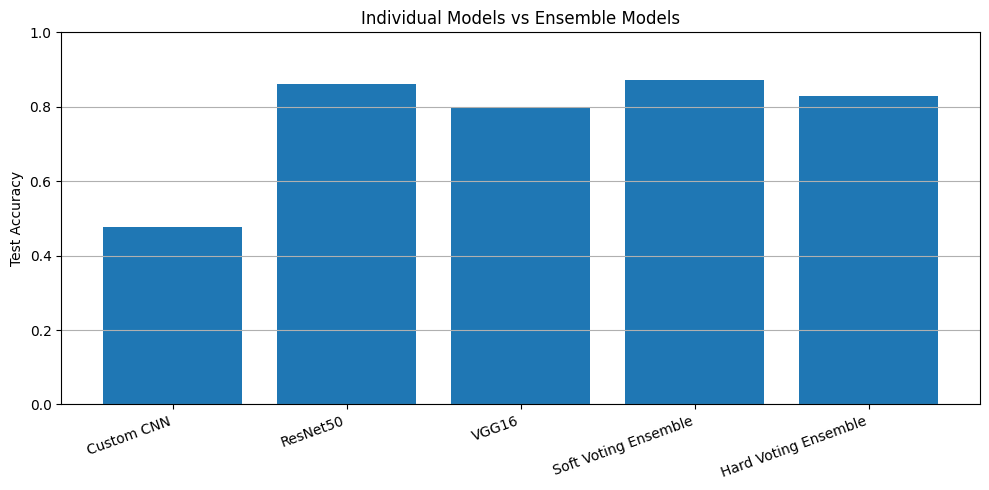

In [21]:
# 18. COMPARE ALL MODELS AND ENSEMBLES

all_results = pd.DataFrame({
    "Model": [
        "Custom CNN", "ResNet50", "VGG16",
        "Soft Voting Ensemble", "Hard Voting Ensemble"
    ],
    "Test Accuracy": [
        custom_acc, resnet_acc, vgg_acc,
        soft_voting_accuracy, hard_voting_accuracy
    ]
})

display(all_results.sort_values("Test Accuracy", ascending=False))

plt.figure(figsize=(10, 5))
plt.bar(all_results["Model"], all_results["Test Accuracy"])
plt.title("Individual Models vs Ensemble Models")
plt.ylabel("Test Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

In [22]:
# 19. CLASSIFICATION REPORT FOR SOFT-VOTING ENSEMBLE

print(classification_report(
    y_test,
    soft_voting_pred,
    target_names=class_names,
    zero_division=0
))

              precision    recall  f1-score   support

    airplane       0.90      0.90      0.90       100
  automobile       0.90      0.94      0.92       100
        bird       0.89      0.77      0.82       100
         cat       0.79      0.78      0.78       100
        deer       0.81      0.86      0.83       100
         dog       0.77      0.82      0.80       100
        frog       0.90      0.93      0.92       100
       horse       0.95      0.90      0.92       100
        ship       0.88      0.94      0.91       100
       truck       0.95      0.87      0.91       100

    accuracy                           0.87      1000
   macro avg       0.87      0.87      0.87      1000
weighted avg       0.87      0.87      0.87      1000



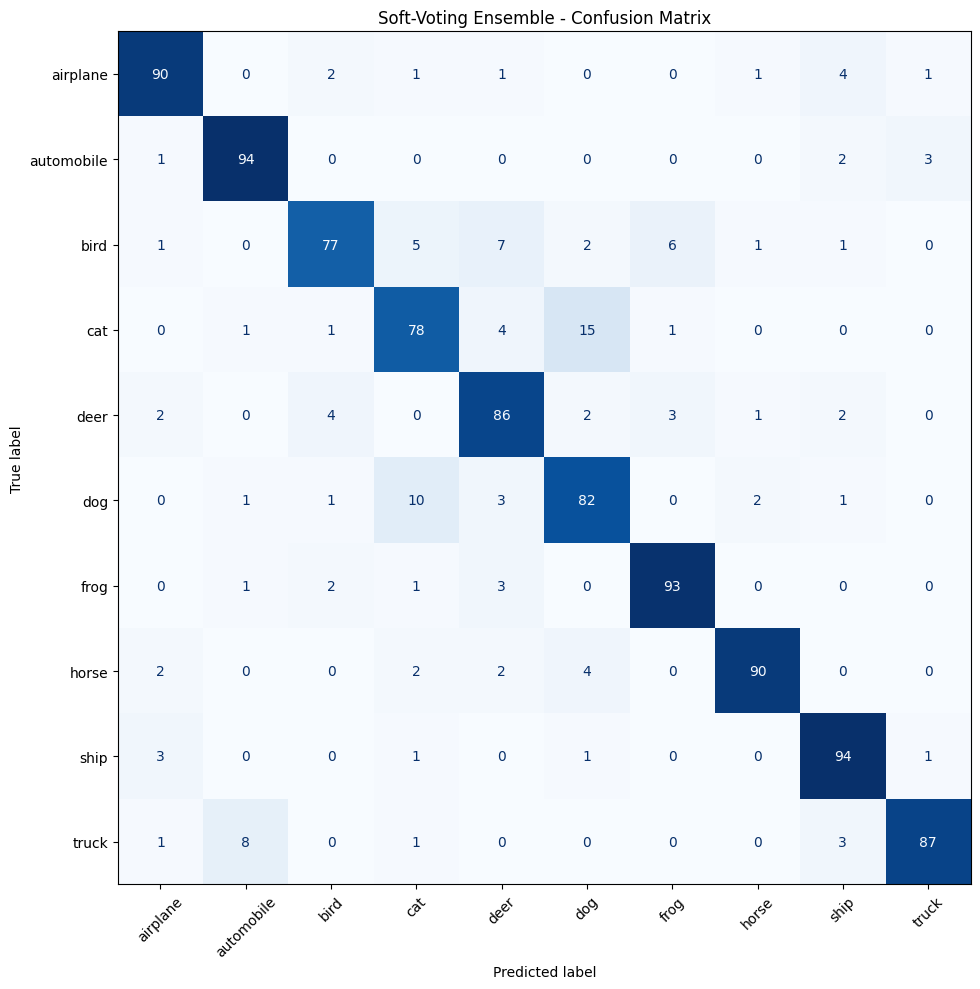

In [23]:
# 20. CONFUSION MATRIX FOR SOFT-VOTING ENSEMBLE

cm = confusion_matrix(y_test, soft_voting_pred)

fig, ax = plt.subplots(figsize=(10, 10))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
).plot(
    ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False
)

plt.title("Soft-Voting Ensemble - Confusion Matrix")
plt.tight_layout()
plt.show()

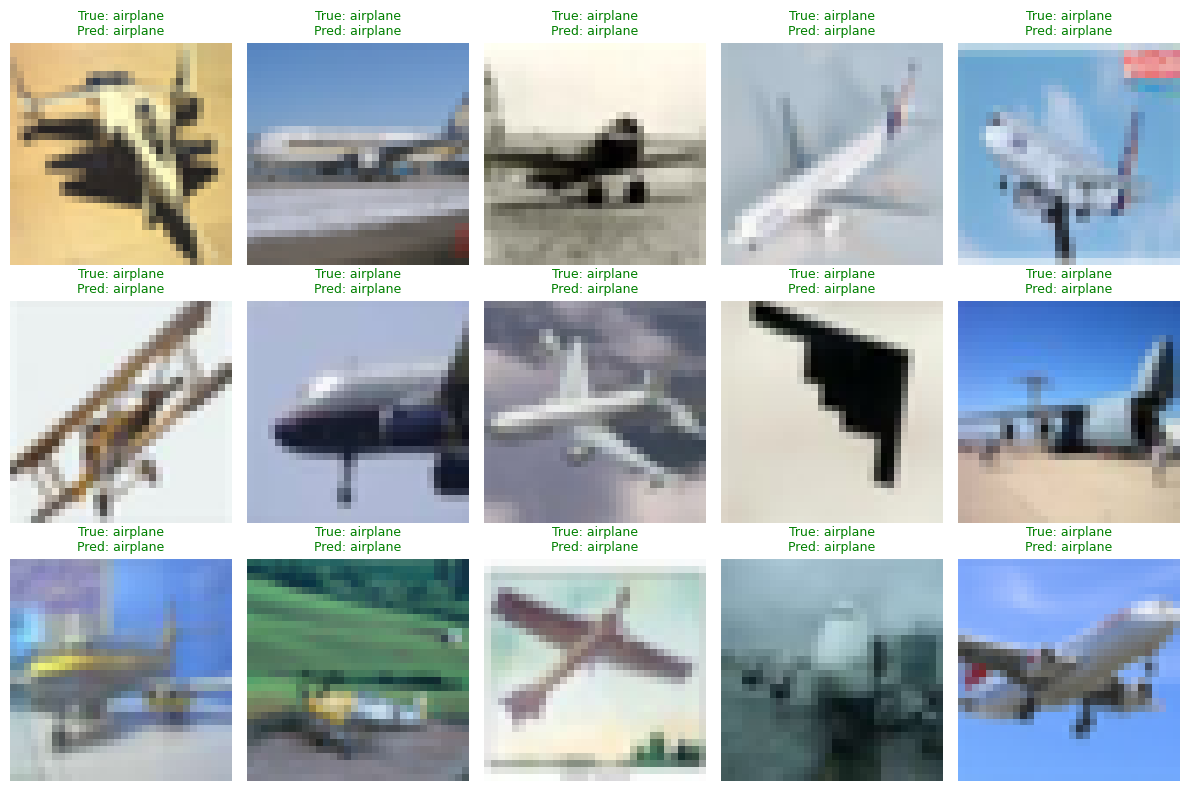

In [24]:
# 21. DISPLAY SAMPLE ENSEMBLE PREDICTIONS

plt.figure(figsize=(12, 8))

for i in range(15):
    plt.subplot(3, 5, i + 1)
    plt.imshow(x_test[i])

    true_label = class_names[y_test[i]]
    predicted_label = class_names[soft_voting_pred[i]]
    title_color = "green" if y_test[i] == soft_voting_pred[i] else "red"

    plt.title(
        f"True: {true_label}\nPred: {predicted_label}",
        color=title_color,
        fontsize=9
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

## 9. Save trained models

The models and comparison table are saved to the Colab `/content` directory. Download them from the Files panel if needed.

In [25]:
# 22. SAVE THE MODELS AND RESULTS

custom_model.save("/content/custom_cnn_cifar10.keras")
resnet_model.save("/content/resnet50_transfer_cifar10.keras")
vgg_model.save("/content/vgg16_transfer_cifar10.keras")

all_results.to_csv("/content/ensemble_model_results.csv", index=False)

print("All models and results saved successfully.")

All models and results saved successfully.


## Conclusion

Transfer learning was implemented using ImageNet-pretrained ResNet50 and VGG16 architectures. Their original classification heads were replaced with custom 10-class heads. The feature extractors were initially frozen and then partially fine-tuned using a limited subset of CIFAR-10.

A custom CNN was trained from scratch. Predictions from the three models were combined using soft voting and hard voting, and the resulting test accuracies were compared.

**Note:** Ensemble methods do not guarantee an improvement in every run. Record the actual accuracy values produced by your Colab execution.